# Diffusion Policy — Windows RTX 4000 Ada local quick test

Adapted from the team notebook for **VS Code + Python 3.12 + CUDA on Windows**. Experimental model, splits, and training settings remain unchanged. Start with `QUICK_TEST=True` (300 steps). Results save locally; share the completed outputs with the team.


In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

Python: c:\Users\rrbhat\Projects\dp_memorization\.venv\Scripts\python.exe
PyTorch: 2.14.1+cu130
CUDA: 13.0
GPU available: True
GPU: NVIDIA RTX 4000 Ada Generation
VRAM: 19.99 GB


In [2]:
import os
import shutil
import subprocess
import sys

GIT_DIR = r"C:\Users\rrbhat\AppData\Local\Programs\Git\cmd"

os.environ["PATH"] = GIT_DIR + os.pathsep + os.environ["PATH"]

print("Git executable:", shutil.which("git"))

Git executable: C:\Users\rrbhat\AppData\Local\Programs\Git\cmd\git.EXE


## Step 1: Run settings

In [3]:
# ===================== Edit these for each run =====================
N_DEMOS = 50          # 10, 25, 50 or 90 (from one pool), or 186 (both pools)
POOL = "B"            # "A" or "B" when N_DEMOS <= 90; "AB" when N_DEMOS == 186
SEED = 2               # 1 or 2
TOTAL_STEPS = 100_000  # gradient steps; the same for every run (fix it after the pilot)
QUICK_TEST = True     # True = tiny run that only checks the setup end to end

# ===================== Usually left as is =====================
PROJECT_DIR = None  # Step 2 selects a local Windows project results folder
EVAL_EPISODES = 50                   # final test episodes (fixed seeds 100000-100049)
EVAL_DURING_TRAINING_EVERY = 10_000  # quick 10-episode check while training (0 = off)
CKPT_EVERY = 10_000                  # how often the resume checkpoint is saved
MILESTONES = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000]  # EMA snapshots for the training-time analysis
SAVE_MILESTONES = (SEED == 1)        # snapshots only for seed 1, to save Drive space

**Windows setup:** Open this notebook inside the project folder in VS Code and select the `Diffusion Policy (CUDA)` kernel. Install dependencies in Step 3 once; if the kernel needs a restart, rerun the setup cells but skip repeating `%pip install`. Git must be available on PATH to clone the pinned repository.


## Step 2: Mount Google Drive and set up folders

In [4]:
import os, sys, json, time, math, copy, random, shutil, glob, subprocess, types, datetime

# Local Windows execution: no Google Drive mount or Colab imports required.
from pathlib import Path
WORK_DIR = str(Path.cwd().resolve())
PROJECT_DIR = os.path.join(WORK_DIR, "dp_memorization")
print("Working directory:", WORK_DIR)

# ---- validate the run settings
assert SEED in (1, 2), "SEED must be 1 or 2"
if N_DEMOS == 186:
    assert POOL == "AB", 'Use POOL = "AB" when N_DEMOS = 186'
else:
    assert N_DEMOS in (10, 25, 50, 90), "N_DEMOS must be 10, 25, 50, 90 or 186"
    assert POOL in ("A", "B"), 'Use POOL = "A" or "B" when N_DEMOS <= 90'

if QUICK_TEST:
    TOTAL_STEPS = 300
    EVAL_EPISODES = 4
    EVAL_DURING_TRAINING_EVERY = 200
    CKPT_EVERY = 200
    MILESTONES = [100, 200]
    SAVE_MILESTONES = True

RUN_NAME = f"N{N_DEMOS:03d}_pool{POOL}_seed{SEED}"
SUBDIR = "quicktest" if QUICK_TEST else "runs"
RUN_DIR = os.path.join(PROJECT_DIR, SUBDIR, RUN_NAME)
RESULTS_DIR = os.path.join(PROJECT_DIR, "results_quicktest" if QUICK_TEST else "results")
DATA_CACHE_DIR = os.path.join(PROJECT_DIR, "data")   # the downloaded zip is cached on Drive
LOCAL_DATA_DIR = os.path.join(WORK_DIR, "data")       # unzipped locally each session (fast)
for d in (RUN_DIR, RESULTS_DIR, DATA_CACHE_DIR, LOCAL_DATA_DIR):
    os.makedirs(d, exist_ok=True)

LATEST_CKPT = os.path.join(RUN_DIR, "latest.pt")
FINAL_MODEL = os.path.join(RUN_DIR, "final_ema_fp16.pt")
print("Run:", RUN_NAME, "| steps:", TOTAL_STEPS, "| quick test:", QUICK_TEST)
print("Saving to:", RUN_DIR)

Working directory: C:\Users\rrbhat\Downloads
Run: N050_poolB_seed2 | steps: 300 | quick test: True
Saving to: C:\Users\rrbhat\Downloads\dp_memorization\quicktest\N050_poolB_seed2


## Step 3: Install packages and get the Diffusion Policy code
We use the authors' code, pinned to a fixed commit so every run uses identical code. The version pins keep it compatible with current Colab.

In [4]:
# Install notebook dependencies into the selected VS Code kernel environment.
# Run once. CUDA-enabled torch must already be installed and verified.
%pip install "zarr>=2.18,<3" "numcodecs>=0.12,<0.16" "pymunk>=6.6,<7" einops diffusers pygame shapely scikit-image numba pandas pillow matplotlib opencv-python tqdm


   ---------------------------------------- 0.0/847.9 kB ? eta -:--:--
   ---------------------------------------- 847.9/847.9 kB 18.9 MB/s  0:00:00
   ---------------------------------------- 0.0/6.5 MB ? eta -:--:--
   ------------------- -------------------- 3.1/6.5 MB 14.2 MB/s eta 0:00:01
   -------------------------------------- - 6.3/6.5 MB 15.4 MB/s eta 0:00:01
   ---------------------------------------- 6.5/6.5 MB 15.4 MB/s  0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 19.2 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ------------------------ --------------- 2.4/3.9 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------- 3.9/3.9 MB 9.3 MB/s  0:00:00
   ---------------------------------------- 0.0/10.6 MB ? eta -:--:--
   ------- -------------------------------- 2.1/10.6 MB 10.7 MB/s eta 0:00:01
   ----------------- -----------------

In [5]:
REPO_DIR = os.path.join(WORK_DIR, "diffusion_policy")
REPO_COMMIT = "5ba07ac6661db573af695b419a7947ecb704690f"
if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "-q", "https://github.com/real-stanford/diffusion_policy.git", REPO_DIR], check=True)
subprocess.run(["git", "-C", REPO_DIR, "checkout", "-q", REPO_COMMIT], check=True)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

# ---- compatibility fixes for a current Colab ------------------------------
os.environ["SDL_VIDEODRIVER"] = "dummy"          # pygame without a display
os.environ["PYGAME_HIDE_SUPPORT_PROMPT"] = "1"

# The Push-T environment only uses `gym` for type declarations (Env, spaces.Box,
# and a registration call). A tiny stand-in avoids installing the old gym 0.21.
_gym = types.ModuleType("gym")
_spaces = types.ModuleType("gym.spaces")
_envs = types.ModuleType("gym.envs")
_registration = types.ModuleType("gym.envs.registration")
class _Env:
    metadata = {}
class _Wrapper(_Env):
    def __init__(self, env):
        self.env = env
class _Box:
    def __init__(self, low=None, high=None, shape=None, dtype=None):
        self.low, self.high, self.shape, self.dtype = low, high, shape, dtype
_spaces.Box, _spaces.Dict = _Box, dict
_registration.register = lambda *args, **kwargs: None
_envs.registration = _registration
_gym.Env, _gym.Wrapper, _gym.spaces, _gym.envs = _Env, _Wrapper, _spaces, _envs
sys.modules.update({"gym": _gym, "gym.spaces": _spaces,
                    "gym.envs": _envs, "gym.envs.registration": _registration})

# matplotlib >= 3.9 removed cm.get_cmap, which the keypoint code still calls.
import matplotlib, matplotlib.cm
if not hasattr(matplotlib.cm, "get_cmap"):
    matplotlib.cm.get_cmap = matplotlib.colormaps.get_cmap

# ---- imports ----------------------------------------------------------------
import numpy as np
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from diffusers.schedulers.scheduling_ddpm import DDPMScheduler
from diffusers.optimization import get_cosine_schedule_with_warmup

from diffusion_policy.dataset.pusht_dataset import PushTLowdimDataset
from diffusion_policy.common.sampler import SequenceSampler
from diffusion_policy.model.diffusion.conditional_unet1d import ConditionalUnet1D
from diffusion_policy.policy.diffusion_unet_lowdim_policy import DiffusionUnetLowdimPolicy
from diffusion_policy.model.diffusion.ema_model import EMAModel
from diffusion_policy.env.pusht.pusht_keypoints_env import PushTKeypointsEnv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.version.cuda is not None:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Device:", GPU_NAME, "| torch", torch.__version__)
if device.type == "cpu":
    raise RuntimeError("CUDA GPU not available in this VS Code kernel. Select the project .venv kernel and verify CUDA PyTorch.")

c:\Users\rrbhat\Projects\dp_memorization\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: NVIDIA RTX 4000 Ada Generation | torch 2.14.1+cu130


## Step 4: Download the Push-T dataset
The zip is downloaded once and cached in Drive, then unzipped to the Colab machine each session (unzipping thousands of small files into Drive would be slow).

In [6]:
DATA_URL = "https://diffusion-policy.cs.columbia.edu/data/training/pusht.zip"
cached_zip = os.path.join(DATA_CACHE_DIR, "pusht.zip")

def find_zarr():
    return glob.glob(os.path.join(LOCAL_DATA_DIR, "**", "pusht_cchi_v7_replay.zarr"), recursive=True)

if not find_zarr():
    from urllib.request import urlretrieve
    from zipfile import ZipFile
    if not os.path.exists(cached_zip):
        print("Downloading Push-T data ...")
        urlretrieve(DATA_URL, cached_zip)
    print("Extracting Push-T data ...")
    with ZipFile(cached_zip) as zf:
        zf.extractall(LOCAL_DATA_DIR)
if not find_zarr():
    raise FileNotFoundError("Push-T .zarr dataset not found after extraction")

ZARR_PATH = find_zarr()[0]
print("Dataset:", ZARR_PATH)

Extracting Push-T data ...
Dataset: C:\Users\rrbhat\Downloads\data\pusht\pusht_cchi_v7_replay.zarr


## Step 5: Helper functions
Data splits, rollouts in the simulator, and the lookup-table baseline. These match the authors' evaluation protocol: two stacked observations, 8 actions executed per prediction, at most 300 environment steps, and the score is the best target coverage reached during the episode.

In [7]:
OBS_DIM, ACTION_DIM = 20, 2           # 9 block keypoints (x, y) + agent position; 2D target
HORIZON, N_OBS_STEPS, N_ACTION_STEPS = 16, 2, 8
MAX_ENV_STEPS = 300
TEST_SEEDS = list(range(100000, 100000 + 50))   # same as the authors' test seeds
MONITOR_SEEDS = list(range(0, 10))              # used only for checks during training


def make_splits(n_episodes=206, n_heldout=20, pool_size=93, split_seed=2026):
    # Fixed random split: 20 held-out demos, then two disjoint pools of 93.
    # The order inside each pool is random, so the first N of a pool is a
    # nested subset (N=10 is inside N=25, which is inside N=50, and so on).
    assert n_heldout + 2 * pool_size == n_episodes
    perm = np.random.default_rng(split_seed).permutation(n_episodes)
    return {
        "split_seed": split_seed,
        "heldout": sorted(int(i) for i in perm[:n_heldout]),
        "pool_A": [int(i) for i in perm[n_heldout:n_heldout + pool_size]],
        "pool_B": [int(i) for i in perm[n_heldout + pool_size:]],
    }


def training_episodes(splits, n_demos, pool):
    if pool == "AB":
        return sorted(splits["pool_A"] + splits["pool_B"])
    return sorted(splits[f"pool_{pool}"][:n_demos])


def stack_last_n_obs(history, n):
    # Same as the authors' MultiStepWrapper: repeat the first obs when history is short.
    h = history[-n:]
    if len(h) < n:
        h = [h[0]] * (n - len(h)) + h
    return np.stack(h)


def run_rollouts(make_env, seeds, policy_fn, max_steps=MAX_ENV_STEPS, record_chunks=False,
                 render_index=None, desc="rollouts"):
    # Runs one episode per seed, all in lockstep so the policy is called on a batch.
    # policy_fn(obs (B, 2, 20) float32) -> (actions (B, 8, 2), full chunk (B, 16, 2) or None)
    envs, histories = [], []
    for s in seeds:
        env = make_env()
        env.seed(s)
        histories.append([env.reset()])
        envs.append(env)
    n = len(envs)
    rewards = [[] for _ in range(n)]
    done = [False] * n
    frames = []
    if render_index is not None:
        frames.append(envs[render_index].render("rgb_array"))
    rec_obs, rec_chunks, rec_episode = [], [], []
    pbar = tqdm(total=max_steps, desc=desc, leave=False)
    progress = 0
    while not all(done):
        active = [i for i in range(n) if not done[i]]
        obs = np.stack([stack_last_n_obs(histories[i], N_OBS_STEPS) for i in active])
        obs = obs[..., :OBS_DIM].astype(np.float32)    # env obs = 20 values + 20 visibility flags
        actions, chunks = policy_fn(obs)
        if record_chunks and chunks is not None:
            rec_obs.append(obs); rec_chunks.append(chunks); rec_episode.append(np.array(active))
        for j, i in enumerate(active):
            for a in actions[j]:
                o, r, d, _ = envs[i].step(a)
                histories[i].append(o)
                rewards[i].append(float(r))
                if i == render_index:
                    frames.append(envs[i].render("rgb_array"))
                if len(rewards[i]) >= max_steps:
                    d = True
                if d:
                    done[i] = True
                    break
        new_progress = max(len(r) for r in rewards)
        pbar.update(new_progress - progress); progress = new_progress
    pbar.close()
    scores = np.array([max(r) if r else 0.0 for r in rewards])
    out = {"scores": scores, "success": scores >= 1.0 - 1e-9}
    if record_chunks:
        out["obs"] = np.concatenate(rec_obs) if rec_obs else np.zeros((0, N_OBS_STEPS, OBS_DIM), np.float32)
        out["chunks"] = np.concatenate(rec_chunks) if rec_chunks else np.zeros((0, HORIZON, ACTION_DIM), np.float32)
        out["episode"] = np.concatenate(rec_episode) if rec_episode else np.zeros((0,), int)
    if render_index is not None:
        out["frames"] = frames
    return out


class LookupPolicy:
    # Nearest-neighbor action lookup: find the training observation history closest to
    # the current one and replay the action chunk that followed it in the demonstration.
    def __init__(self, keys, chunks, obs_min, obs_max):
        # keys: (K, 2, 20) observation histories; chunks: (K, 16, 2) action chunks
        rng = np.maximum(obs_max - obs_min, 1e-4)
        self.scale = (2.0 / rng).astype(np.float32)          # map each obs dim to [-1, 1]
        self.offset = (-1.0 - obs_min * self.scale).astype(np.float32)
        self.keys = self._norm(keys).reshape(len(keys), -1)
        self.key_sq = (self.keys ** 2).sum(1)
        self.chunks = chunks.astype(np.float32)

    def _norm(self, obs):
        return obs.astype(np.float32) * self.scale + self.offset

    def nearest(self, obs):
        q = self._norm(obs).reshape(len(obs), -1)
        d2 = (q ** 2).sum(1)[:, None] + self.key_sq[None, :] - 2.0 * q @ self.keys.T
        return d2.argmin(1)

    def __call__(self, obs):
        chunk = self.chunks[self.nearest(obs)]
        # Same convention as Diffusion Policy: chunk index 0 is the previous step,
        # so the 8 executed actions are indices 1..8.
        return chunk[:, N_OBS_STEPS - 1:N_OBS_STEPS - 1 + N_ACTION_STEPS], chunk

## Step 6: Load the data and build the fixed splits
The splits are generated from a fixed seed, so everyone gets the same ones. They are also saved to Drive and checked on every run.

In [8]:
dataset = PushTLowdimDataset(zarr_path=ZARR_PATH, horizon=HORIZON,
                             pad_before=N_OBS_STEPS - 1, pad_after=N_ACTION_STEPS - 1,
                             val_ratio=0.0, max_train_episodes=None)
episode_ends = dataset.replay_buffer.episode_ends[:]
n_episodes = len(episode_ends)
print(f"{n_episodes} demonstrations, {int(episode_ends[-1])} timesteps")
assert n_episodes == 206, "Unexpected dataset: expected 206 demonstrations"

splits = make_splits(n_episodes)
splits_path = os.path.join(PROJECT_DIR, "splits.json")
if os.path.exists(splits_path):
    with open(splits_path) as f:
        assert json.load(f) == splits, "splits.json on Drive differs from the fixed splits!"
else:
    with open(splits_path, "w") as f:
        json.dump(splits, f, indent=1)

train_eps = training_episodes(splits, N_DEMOS, POOL)
assert len(train_eps) == N_DEMOS and not set(train_eps) & set(splits["heldout"])
train_mask = np.zeros(n_episodes, dtype=bool)
train_mask[train_eps] = True

# Train only on the chosen episodes (same windowing and padding as the authors' code).
dataset.sampler = SequenceSampler(replay_buffer=dataset.replay_buffer, sequence_length=HORIZON,
                                  pad_before=N_OBS_STEPS - 1, pad_after=N_ACTION_STEPS - 1,
                                  episode_mask=train_mask)
dataset.train_mask = train_mask
# The normalizer is fit on the full dataset (authors' default), so it is identical for every run.
normalizer = dataset.get_normalizer()
print(f"Training on {N_DEMOS} demos -> {len(dataset)} training windows")

206 demonstrations, 25650 timesteps
Training on 50 demos -> 5718 training windows


## Step 7: Build the policy and run quick checks
Model and training settings are the authors' published ones for state-based Push-T: a 1D convolutional U-Net, 100 diffusion steps, batch 256, AdamW with learning rate 1e-4, and EMA weights for evaluation.

In [9]:
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def build_policy():
    model = ConditionalUnet1D(input_dim=ACTION_DIM, local_cond_dim=None,
                              global_cond_dim=OBS_DIM * N_OBS_STEPS, diffusion_step_embed_dim=256,
                              down_dims=[256, 512, 1024], kernel_size=5, n_groups=8,
                              cond_predict_scale=True)
    scheduler = DDPMScheduler(num_train_timesteps=100, beta_start=0.0001, beta_end=0.02,
                              beta_schedule="squaredcos_cap_v2", variance_type="fixed_small",
                              clip_sample=True, prediction_type="epsilon")
    p = DiffusionUnetLowdimPolicy(model=model, noise_scheduler=scheduler, horizon=HORIZON,
                                  obs_dim=OBS_DIM, action_dim=ACTION_DIM,
                                  n_action_steps=N_ACTION_STEPS, n_obs_steps=N_OBS_STEPS,
                                  num_inference_steps=100, obs_as_local_cond=False,
                                  obs_as_global_cond=True, pred_action_steps_only=False,
                                  oa_step_convention=True)
    p.set_normalizer(normalizer)
    return p

policy = build_policy()
ema_policy = copy.deepcopy(policy)
policy.to(device); ema_policy.to(device)
ema = EMAModel(ema_policy, update_after_step=0, inv_gamma=1.0, power=0.75, min_value=0.0, max_value=0.9999)
optimizer = torch.optim.AdamW(policy.parameters(), lr=1e-4, betas=(0.95, 0.999), eps=1e-8, weight_decay=1e-6)
lr_scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=500, num_training_steps=TOTAL_STEPS)
n_params = sum(p.numel() for p in policy.model.parameters())
print(f"Diffusion model: {n_params / 1e6:.1f}M parameters")

KP_KWARGS = PushTKeypointsEnv.genenerate_keypoint_manager_params()  # keypoint definition (authors' code)
def make_env(render_size=96):
    return PushTKeypointsEnv(legacy=True, keypoint_visible_rate=1.0, agent_keypoints=False,
                             render_size=render_size, **KP_KWARGS)

@torch.no_grad()
def dp_policy_fn(obs_np, p=None):
    p = ema_policy if p is None else p
    out = p.predict_action({"obs": torch.from_numpy(obs_np).to(device)})
    return out["action"].cpu().numpy(), out["action_pred"].cpu().numpy()

# ---- quick checks: simulator, data, model --------------------------------------
env = make_env(); env.seed(TEST_SEEDS[0]); o = env.reset()
assert o.shape == (2 * OBS_DIM,), o.shape
o2, r, d, _ = env.step(o[OBS_DIM - 2:OBS_DIM])          # move to the agent's own position
assert 0.0 <= r <= 1.0
sample = dataset[0]
assert tuple(sample["obs"].shape) == (HORIZON, OBS_DIM) and tuple(sample["action"].shape) == (HORIZON, ACTION_DIM)
batch = {k: v[None].to(device) for k, v in sample.items()}
loss = policy.compute_loss(batch)
assert torch.isfinite(loss)
acts, chunk = dp_policy_fn(np.stack([stack_last_n_obs([o[:OBS_DIM].astype(np.float32)], 2)] * 2))
assert acts.shape == (2, N_ACTION_STEPS, ACTION_DIM) and chunk.shape == (2, HORIZON, ACTION_DIM)
optimizer.zero_grad(set_to_none=True)
print("All checks passed: simulator, dataset and model work.")

Diffusion model: 65.8M parameters
All checks passed: simulator, dataset and model work.


## Step 8: Train
Every run uses the same number of gradient steps (`TOTAL_STEPS`), whatever the dataset size. Progress is saved to Drive; re-running this cell after a disconnect resumes from the last checkpoint. If the final model already exists, training is skipped.

In [10]:
def save_ema_fp16(path):
    # Model weights in half precision (~130 MB); normalizer kept in full precision.
    sd = {k: (v.half() if v.is_floating_point() and "normalizer" not in k else v).cpu()
          for k, v in ema_policy.state_dict().items()}
    tmp = path + ".tmp"
    torch.save(sd, tmp); os.replace(tmp, path)

def save_resume_checkpoint(step):
    tmp = LATEST_CKPT + ".tmp"
    torch.save({"step": step, "policy": policy.state_dict(), "ema_policy": ema_policy.state_dict(),
                "optimizer": optimizer.state_dict(), "lr_scheduler": lr_scheduler.state_dict(),
                "ema_optimization_step": ema.optimization_step}, tmp)
    os.replace(tmp, LATEST_CKPT)

def append_csv(path, row):
    new = not os.path.exists(path)
    with open(path, "a") as f:
        if new:
            f.write(",".join(row.keys()) + "\n")
        f.write(",".join(str(v) for v in row.values()) + "\n")

with open(os.path.join(RUN_DIR, "config.json"), "w") as f:
    json.dump({"run_name": RUN_NAME, "n_demos": N_DEMOS, "pool": POOL, "seed": SEED,
               "total_steps": TOTAL_STEPS, "train_episodes": train_eps, "repo_commit": REPO_COMMIT,
               "quick_test": QUICK_TEST}, f, indent=1)

train_time_min = None
if os.path.exists(FINAL_MODEL):
    print("Final model already exists; skipping training.")
    ema_policy.load_state_dict(torch.load(FINAL_MODEL, map_location=device))
else:
    step = 0
    if os.path.exists(LATEST_CKPT):
        ckpt = torch.load(LATEST_CKPT, map_location=device, weights_only=False)
        policy.load_state_dict(ckpt["policy"]); ema_policy.load_state_dict(ckpt["ema_policy"])
        optimizer.load_state_dict(ckpt["optimizer"]); lr_scheduler.load_state_dict(ckpt["lr_scheduler"])
        ema.optimization_step = ckpt["ema_optimization_step"]
        step = ckpt["step"]
        del ckpt
        print(f"Resuming from step {step}")

    # Windows Jupyter: workers=0 avoids multiprocessing spawn/pickling issues.
    # Batch size and training math are unchanged from team notebook.
    loader = DataLoader(dataset, batch_size=256, shuffle=True, num_workers=0,
                        pin_memory=True, persistent_workers=False)
    def endless(dl):
        while True:
            for b in dl:
                yield b
    batches = endless(loader)

    loss_log = os.path.join(RUN_DIR, "train_loss.csv")
    eval_log = os.path.join(RUN_DIR, "train_eval.csv")
    policy.train()
    t_start, step_start, running = time.time(), step, []
    pbar = tqdm(total=TOTAL_STEPS, initial=step, desc="training", mininterval=5)
    while step < TOTAL_STEPS:
        batch = {k: v.to(device, non_blocking=True) for k, v in next(batches).items()}
        loss = policy.compute_loss(batch)
        loss.backward()
        optimizer.step(); optimizer.zero_grad(set_to_none=True)
        lr_scheduler.step()
        ema.step(policy)
        step += 1
        running.append(loss.item() if step % 50 == 0 else None)
        pbar.update(1)

        if step % 500 == 0 or step == TOTAL_STEPS:
            vals = [x for x in running if x is not None]
            append_csv(loss_log, {"step": step, "loss": np.mean(vals) if vals else float("nan"),
                                  "lr": lr_scheduler.get_last_lr()[0],
                                  "elapsed_min": round((time.time() - t_start) / 60, 2)})
            pbar.set_postfix(loss=f"{np.mean(vals):.4f}" if vals else "-")
            running = []
        if SAVE_MILESTONES and step in MILESTONES:
            save_ema_fp16(os.path.join(RUN_DIR, f"ema_step{step:06d}_fp16.pt"))
        if EVAL_DURING_TRAINING_EVERY and step % EVAL_DURING_TRAINING_EVERY == 0 and step < TOTAL_STEPS:
            seeds = MONITOR_SEEDS[:2] if QUICK_TEST else MONITOR_SEEDS
            res = run_rollouts(make_env, seeds, dp_policy_fn, desc=f"check @ {step}")
            append_csv(eval_log, {"step": step, "mean_score": round(float(res["scores"].mean()), 4),
                                  "success_rate": round(float(res["success"].mean()), 4)})
            tqdm.write(f"step {step:>7}: quick check on {len(seeds)} episodes -> "
                       f"mean score {res['scores'].mean():.3f}, success {res['success'].mean():.0%}")
        if step % CKPT_EVERY == 0 and step < TOTAL_STEPS:
            save_resume_checkpoint(step)
    pbar.close()

    elapsed = time.time() - t_start
    steps_done = step - step_start
    train_time_min = elapsed / 60
    save_ema_fp16(FINAL_MODEL)
    if os.path.exists(LATEST_CKPT):
        os.remove(LATEST_CKPT)
    if steps_done > 0:
        sec_per_step = elapsed / steps_done
        full_hours = sec_per_step * TOTAL_STEPS / 3600
        print(f"Trained {steps_done} steps in {elapsed / 60:.1f} min on {GPU_NAME} "
              f"({1 / sec_per_step:.1f} steps/s, excluding the quick checks would be a bit faster).")
        print(f"A full run of {TOTAL_STEPS:,} steps takes about {full_hours:.1f} h on this GPU.")
print("Training done.")

training:  67%|██████▋   | 200/300 [00:30<00:05, 18.01it/s]

step     200: quick check on 2 episodes -> mean score 0.099, success 0%


training: 100%|██████████| 300/300 [00:36<00:00,  8.27it/s, loss=0.2531]

Trained 300 steps in 0.6 min on NVIDIA RTX 4000 Ada Generation (8.3 steps/s, excluding the quick checks would be a bit faster).
A full run of 300 steps takes about 0.0 h on this GPU.
Training done.


## Step 9: Evaluate Diffusion Policy and the lookup baseline
Both are tested on the same 50 fixed starting positions. The action chunks Diffusion Policy produces during these rollouts are saved for the memorization analysis in the next notebook.

The lookup baseline has no randomness, so it only needs one evaluation per training set; it runs on seed-1 runs (or whenever its result is missing).

In [11]:
def save_result(result):
    path = os.path.join(RESULTS_DIR, result["run_name"] + ".json")
    with open(path, "w") as f:
        json.dump(result, f, indent=1)

seeds = TEST_SEEDS[:EVAL_EPISODES]
ema_policy.eval()
common = {"n_demos": N_DEMOS, "pool": POOL, "eval_episodes": len(seeds), "gpu": GPU_NAME,
          "timestamp": datetime.datetime.now().isoformat(timespec="seconds")}

# ---- Diffusion Policy
t0 = time.time()
res = run_rollouts(make_env, seeds, dp_policy_fn, record_chunks=True, desc="Diffusion Policy eval")
np.savez_compressed(os.path.join(RUN_DIR, "rollout_chunks.npz"), obs=res["obs"], chunks=res["chunks"],
                    episode=res["episode"], seeds=np.array(seeds), scores=res["scores"])
dp_result = {"run_name": RUN_NAME, "method": "diffusion_policy", "seed": SEED,
             "total_steps": TOTAL_STEPS, "train_time_min": train_time_min,
             "mean_score": float(res["scores"].mean()), "success_rate": float(res["success"].mean()),
             "scores": res["scores"].round(4).tolist(), **common}
save_result(dp_result)
print(f"Diffusion Policy ({RUN_NAME}): mean score {dp_result['mean_score']:.3f}, "
      f"success {dp_result['success_rate']:.0%}  [{(time.time() - t0) / 60:.1f} min]")

# ---- Lookup baseline (built from exactly the windows Diffusion Policy trains on)
lookup_name = f"N{N_DEMOS:03d}_pool{POOL}_lookup"
if SEED == 1 or not os.path.exists(os.path.join(RESULTS_DIR, lookup_name + ".json")):
    keys, chunks = [], []
    for i in range(len(dataset.sampler)):
        w = dataset._sample_to_data(dataset.sampler.sample_sequence(i))
        keys.append(w["obs"][:N_OBS_STEPS]); chunks.append(w["action"])
    full = dataset._sample_to_data(dataset.replay_buffer)       # full data, for normalization
    lookup = LookupPolicy(np.stack(keys), np.stack(chunks),
                          full["obs"].min(0), full["obs"].max(0))
    res_nn = run_rollouts(make_env, seeds, lookup, desc="lookup baseline eval")
    nn_result = {"run_name": lookup_name, "method": "lookup", "seed": None, "total_steps": 0,
                 "train_time_min": 0, "mean_score": float(res_nn["scores"].mean()),
                 "success_rate": float(res_nn["success"].mean()),
                 "scores": res_nn["scores"].round(4).tolist(), **common}
    save_result(nn_result)
    print(f"Lookup baseline ({lookup_name}): mean score {nn_result['mean_score']:.3f}, "
          f"success {nn_result['success_rate']:.0%}")

Diffusion Policy (N050_poolB_seed2): mean score 0.342, success 0%  [0.3 min]


Lookup baseline (N050_poolB_lookup): mean score 0.498, success 0%


## Step 10: Results so far (all runs saved to the shared folder)

In [12]:
import pandas as pd
from IPython.display import display
rows = []
for p in sorted(glob.glob(os.path.join(RESULTS_DIR, "*.json"))):
    with open(p) as f:
        r = json.load(f)
    r.pop("scores", None)
    rows.append(r)
if rows:
    table = pd.DataFrame(rows)[["method", "n_demos", "pool", "seed", "mean_score", "success_rate",
                                "total_steps", "train_time_min", "gpu", "timestamp"]]
    display(table.sort_values(["method", "n_demos", "pool", "seed"]).reset_index(drop=True))

,method,n_demos,pool,seed,mean_score,success_rate,total_steps,train_time_min,gpu,timestamp
0,diffusion_policy,50,B,2.0,0.341808,0.0,300,0.604429,NVIDIA RTX 4000 Ada Generation,2026-11-17T16:49:11
1,lookup,50,B,NaN,0.498193,0.0,0,0.000000,NVIDIA RTX 4000 Ada Generation,2026-11-17T16:49:11


## Step 11 (optional): Watch one episode
Saves a short GIF of the trained policy on the first test episode.

Score 0.405 -> C:\Users\rrbhat\Downloads\dp_memorization\quicktest\N050_poolB_seed2\episode_seed100000.gif


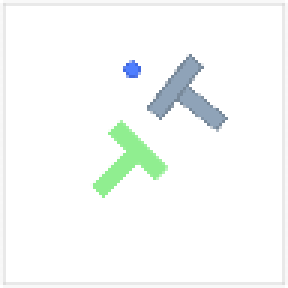

In [13]:
from PIL import Image as PILImage
from IPython.display import Image, display
res_vis = run_rollouts(make_env, [TEST_SEEDS[0]], dp_policy_fn, render_index=0, desc="recording")
gif_path = os.path.join(RUN_DIR, "episode_seed100000.gif")
frames = [PILImage.fromarray(fr).resize((288, 288), PILImage.NEAREST) for fr in res_vis["frames"]]
frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=100, loop=0)
print(f"Score {res_vis['scores'][0]:.3f} ->", gif_path)
display(Image(filename=gif_path))

## Next
When a few runs have finished, notebook 2 will compute the memorization metrics (replay score, memorization ratio, and the disjoint-split test) from the saved models and rollout chunks.